In [1]:
import os
import statistics
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
target_directory = '/images'

In [9]:
def get_file_sizes(directory='.'):
    """Recursively gets file sizes in bytes in a directory."""
    file_sizes = []
    for root, dirs, files in os.walk(directory):
        for file in files:
            file_path = os.path.join(root, file)
            try:
                # Use pathlib for more robust path handling
                size = Path(file_path).stat().st_size
                file_sizes.append(size)
            except OSError:
                # Skip files that cannot be accessed
                continue
    return file_sizes

def analyze_directory(directory='.'):
    sizes = get_file_sizes(directory)

    if not sizes:
        print("No files found or directory is empty.")
        return

    # Convert to MB for better readability in analysis
    sizes_mb = [s / (1024 * 1024) for s in sizes]

    # Calculate Statistics
    mean_size = statistics.mean(sizes_mb)
    median_size = statistics.median(sizes_mb)
    try:
        mode_size = statistics.mode(sizes_mb)
    except statistics.StatisticsError:
        mode_size = "No unique mode"



    # Graph and Distribution
    plt.figure(figsize=(10, 6))
    plt.hist(sizes_mb, bins=50, color='skyblue', edgecolor='black', alpha=0.7)

    # Add lines for mean, median, mode
    plt.axvline(mean_size, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_size:.2f} MB')
    plt.axvline(median_size, color='green', linestyle='dashed', linewidth=2, label=f'Median: {median_size:.2f} MB')

    plt.title(f'File Size Distribution in: {os.path.abspath(directory)}')
    plt.xlabel('File Size (MB)')
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(axis='y', alpha=0.5)
    plt.show()

    print(f"Total Files: {len(sizes)}")
    print(f"Mean Size: {mean_size:.2f} MB")
    print(f"Median Size: {median_size:.2f} MB")
    print(f"Mode Size: {mode_size if isinstance(mode_size, str) else f'{mode_size:.2f} MB'}")

In [10]:

analyze_directory(target_directory)

Total Files: 958
Mean Size: 0.35 MB
Median Size: 0.41 MB
Mode Size: 0.41 MB


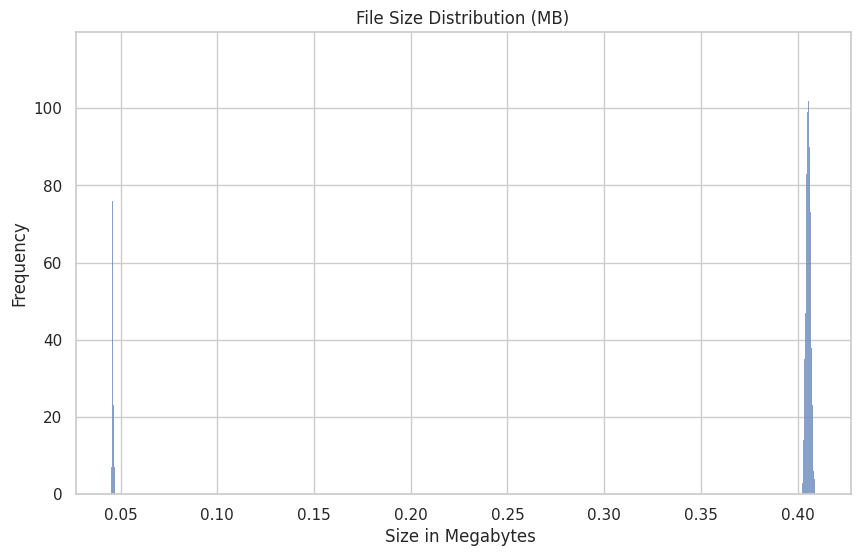

In [7]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get file sizes in a directory

file_sizes = []
for root, dirs, files in os.walk(target_directory):
    for file in files:
        path = os.path.join(root, file)
        try:
            file_sizes.append(os.path.getsize(path) / (1024 * 1024)) # MB
        except OSError:
            pass

# Convert to Pandas DataFrame
df = pd.DataFrame(file_sizes, columns=['Size_MB'])

# 2. Plot the distribution
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
# Using histplot with log scale for skewed data
sns.histplot(data=df, x='Size_MB')
plt.title('File Size Distribution (MB)')
plt.xlabel('Size in Megabytes ')
plt.ylabel('Frequency')
plt.show()
